- Analisis de sensibilidad 
- Jorge Ruiz Esquer 
- lunes 24 de agosto 

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.stats import norm 

In [4]:
#Parametros 


S0 = 100
k = 100
r = 0.05 
sigma = 0.20
T = 1 
M = 10000

np.random.normal(123)

123.99734544658358

## Simulación Monte Carlo

In [6]:
#Generar variables aleatorias 

Z = np.random.normal(0,1,M)

#Simular el pecio del activo

ST = S0 * np.exp(
    (r-sigma**2/2)*T
    +sigma * np.sqrt(T)*Z
    
)



## Call

In [9]:
# Payoff call 

payoff_call = np.maximum(ST- k,0)

# Precio de la call (Monte Carlo)

call_mc = np.exp(-r*T)*np.mean(payoff_call)

## Put 

In [11]:
# Payoff put

payoff_put = np.maximum(k - ST,0)

# Precio de la put (Monte Carlo)

put_mc = np.exp(-r*T)*np.mean(payoff_put)

## Black-Scholes

In [13]:
# Calcular d1
d1 = (
    np.log(S0 / k)
    + (r + sigma**2 / 2) * T
) / (sigma * np.sqrt(T))

# Calcular d2
d2 = d1 - sigma * np.sqrt(T)

## Precios 

In [15]:
# precio call 

call_bs = (
    S0 * norm.cdf(d1)
    - k * np.exp(-r*T) * norm.cdf(d2)
)

# precio put 

put_bs = (
    k * np.exp(-r*T) * norm.cdf(-d2)
    - S0 * norm.cdf(-d1)
)

## Comparación 

In [16]:
print("RESULTADOS")
print("-----------------------------")

print("CALL")
print("Monte Carlo:", call_mc)
print("Black-Scholes:", call_bs)
print("Diferencia:", abs(call_mc - call_bs))

print("\nPUT")
print("Monte Carlo:", put_mc)
print("Black-Scholes:", put_bs)
print("Diferencia:", abs(put_mc - put_bs))

RESULTADOS
-----------------------------
CALL
Monte Carlo: 5.540007656464119
Black-Scholes: 10.450583572185565
Diferencia: 4.910575915721446

PUT
Monte Carlo: 5.540007656464119
Black-Scholes: 5.573526022256971
Diferencia: 0.033518365792851945


## Sensibilidad 

In [19]:
# PRECIOS DEL ACTIVO
S0_valores = np.array([80, 90, 100, 110, 120])

# Vectores para guardar resultados
calls_S0 = []
puts_S0 = []

# Calcular para cada precio del activo
for S in S0_valores:

    d1 = (
        np.log(S / k)
        + (r + sigma**2 / 2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    # Call
    call = S * norm.cdf(d1) - k * np.exp(-r*T) * norm.cdf(d2)

    # Put
    put = k * np.exp(-r*T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    calls_S0.append(call)
    puts_S0.append(put)


# Mostrar resultados
print("S0       Call       Put")

for i in range(len(S0_valores)):
    print(
        S0_valores[i],
        round(calls_S0[i], 4),
        round(puts_S0[i], 4)
    )

S0       Call       Put
80 1.8594 16.9824
90 5.0912 10.2142
100 10.4506 5.5735
110 17.663 2.7859
120 26.169 1.292


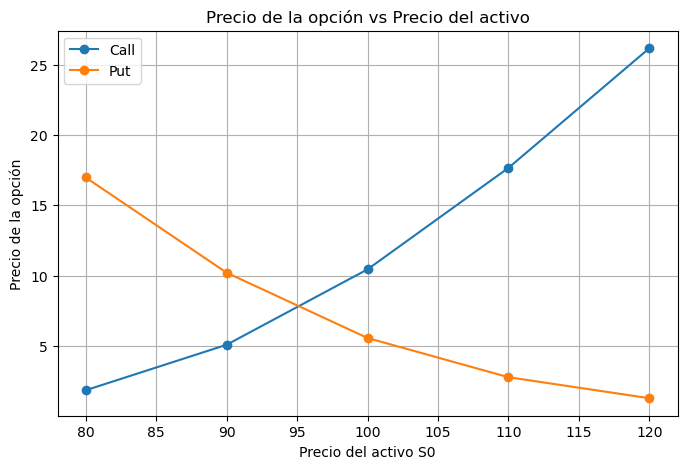

In [20]:
plt.figure(figsize=(8,5))

plt.plot(S0_valores, calls_S0, marker='o', label='Call')
plt.plot(S0_valores, puts_S0, marker='o', label='Put')

plt.xlabel('Precio del activo S0')
plt.ylabel('Precio de la opción')
plt.title('Precio de la opción vs Precio del activo')
plt.legend()
plt.grid(True)

plt.show()

In [21]:
# STRIKES
K_valores = np.array([80, 90, 100, 110, 120])

calls_K = []
puts_K = []

for K_actual in K_valores:

    d1 = (
        np.log(S0 / K_actual)
        + (r + sigma**2 / 2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    # Call
    call = (
        S0 * norm.cdf(d1)
        - K_actual * np.exp(-r*T) * norm.cdf(d2)
    )

    # Put
    put = (
        K_actual * np.exp(-r*T) * norm.cdf(-d2)
        - S0 * norm.cdf(-d1)
    )

    calls_K.append(call)
    puts_K.append(put)


print("K        Call       Put")

for i in range(len(K_valores)):
    print(
        K_valores[i],
        round(calls_K[i], 4),
        round(puts_K[i], 4)
    )

K        Call       Put
80 24.5888 0.6872
90 16.6994 2.3101
100 10.4506 5.5735
110 6.0401 10.6753
120 3.2475 17.395


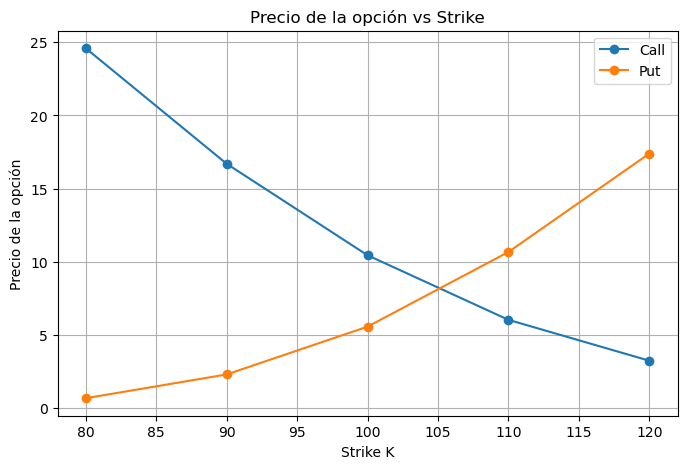

In [22]:
plt.figure(figsize=(8,5))

plt.plot(K_valores, calls_K, marker='o', label='Call')
plt.plot(K_valores, puts_K, marker='o', label='Put')

plt.xlabel('Strike K')
plt.ylabel('Precio de la opción')
plt.title('Precio de la opción vs Strike')
plt.legend()
plt.grid(True)

plt.show()

In [24]:
# VOLATILIDADES
sigma_valores = np.array([0.10, 0.20, 0.30, 0.40, 0.50])

calls_sigma = []
puts_sigma = []

for sigma_actual in sigma_valores:

    d1 = (
        np.log(S0 / k)
        + (r + sigma_actual**2 / 2) * T
    ) / (sigma_actual * np.sqrt(T))

    d2 = d1 - sigma_actual * np.sqrt(T)

    # Call
    call = (
        S0 * norm.cdf(d1)
        - k * np.exp(-r*T) * norm.cdf(d2)
    )

    # Put
    put = (
        k * np.exp(-r*T) * norm.cdf(-d2)
        - S0 * norm.cdf(-d1)
    )

    calls_sigma.append(call)
    puts_sigma.append(put)


print("Sigma       Call       Put")

for i in range(len(sigma_valores)):
    print(
        sigma_valores[i],
        round(calls_sigma[i], 4),
        round(puts_sigma[i], 4)
    )

Sigma       Call       Put
0.1 6.805 1.9279
0.2 10.4506 5.5735
0.3 14.2313 9.3542
0.4 18.023 13.1459
0.5 21.7926 16.9155


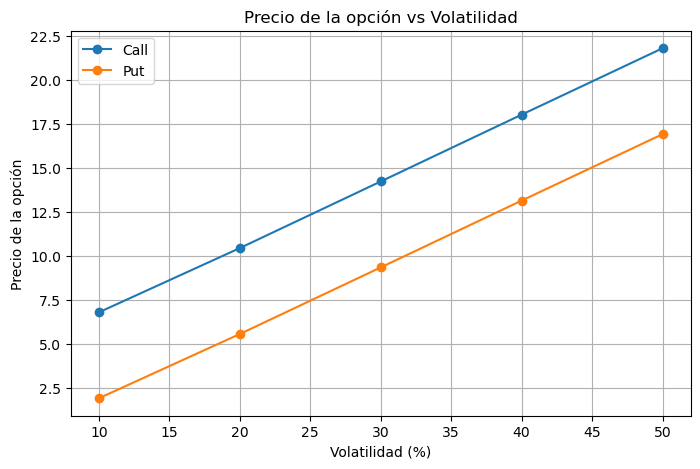

In [25]:
plt.figure(figsize=(8,5))

plt.plot(sigma_valores * 100, calls_sigma, marker='o', label='Call')
plt.plot(sigma_valores * 100, puts_sigma, marker='o', label='Put')

plt.xlabel('Volatilidad (%)')
plt.ylabel('Precio de la opción')
plt.title('Precio de la opción vs Volatilidad')
plt.legend()
plt.grid(True)

plt.show()

In [27]:
# TIEMPO
T_valores = np.array([0.25, 0.5, 1, 1.5, 2])

calls_T = []
puts_T = []

for T_actual in T_valores:

    d1 = (
        np.log(S0 / k)
        + (r + sigma**2 / 2) * T_actual
    ) / (sigma * np.sqrt(T_actual))

    d2 = d1 - sigma * np.sqrt(T_actual)

    # Call
    call = (
        S0 * norm.cdf(d1)
        - k * np.exp(-r*T_actual) * norm.cdf(d2)
    )

    # Put
    put = (
        k * np.exp(-r*T_actual) * norm.cdf(-d2)
        - S0 * norm.cdf(-d1)
    )

    calls_T.append(call)
    puts_T.append(put)


print("T          Call       Put")

for i in range(len(T_valores)):
    print(
        T_valores[i],
        round(calls_T[i], 4),
        round(puts_T[i], 4)
    )

T          Call       Put
0.25 4.615 3.3728
0.5 6.8887 4.4197
1.0 10.4506 5.5735
1.5 13.4429 6.2173
2.0 16.1268 6.6105


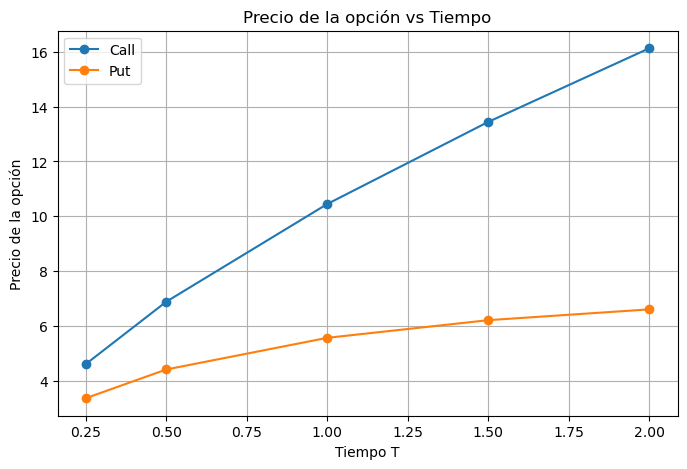

In [28]:
plt.figure(figsize=(8,5))

plt.plot(T_valores, calls_T, marker='o', label='Call')
plt.plot(T_valores, puts_T, marker='o', label='Put')

plt.xlabel('Tiempo T')
plt.ylabel('Precio de la opción')
plt.title('Precio de la opción vs Tiempo')
plt.legend()
plt.grid(True)

plt.show()

In [29]:
# RENDIMIENTOS
r_valores = np.array([0.05, 0.10, 0.15, 0.20])

calls_r = []
puts_r = []

for r_actual in r_valores:

    d1 = (
        np.log(S0 / k)
        + (r_actual + sigma**2 / 2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    # Call
    call = (
        S0 * norm.cdf(d1)
        - k * np.exp(-r_actual*T) * norm.cdf(d2)
    )

    # Put
    put = (
        k * np.exp(-r_actual*T) * norm.cdf(-d2)
        - S0 * norm.cdf(-d1)
    )

    calls_r.append(call)
    puts_r.append(put)


print("r          Call       Put")

for i in range(len(r_valores)):
    print(
        r_valores[i],
        round(calls_r[i], 4),
        round(puts_r[i], 4)
    )

r          Call       Put
0.05 10.4506 5.5735
0.1 13.2697 3.7534
0.15 16.356 2.4268
0.2 19.6299 1.503


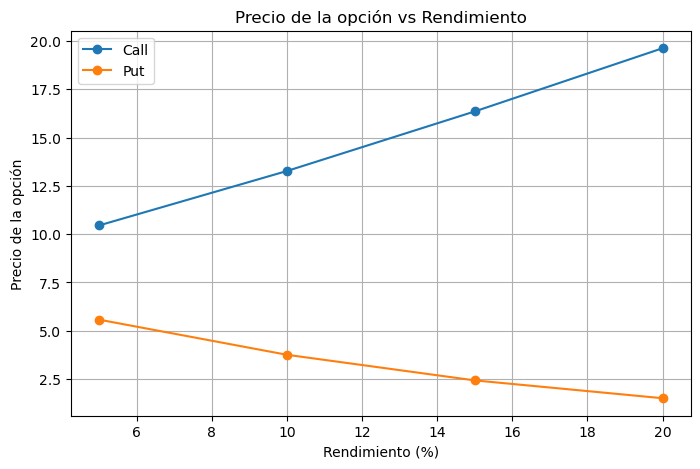

In [30]:
plt.figure(figsize=(8,5))

plt.plot(r_valores * 100, calls_r, marker='o', label='Call')
plt.plot(r_valores * 100, puts_r, marker='o', label='Put')

plt.xlabel('Rendimiento (%)')
plt.ylabel('Precio de la opción')
plt.title('Precio de la opción vs Rendimiento')
plt.legend()
plt.grid(True)

plt.show()

## Interpretación

Precio del activo

### ¿Por qué una call aumenta cuando aumenta el precio de la acción?

Una call es una opción que otorga al comprador el derecho, pero no la obligación, de comprar el activo a un precio determinado llamado strike (K). Por lo tanto, cuando aumenta el precio del activo (S_0), resulta más atractivo tener el derecho de comprarlo al precio establecido.

### ¿Por qué una put se comporta de manera distinta?

Una put otorga el derecho a vender el activo a un precio determinado (K). Por ello, cuando aumenta el precio del activo, este derecho se vuelve menos atractivo.
Por ejemplo, si (K=100) y el activo tiene un precio de 80 venderlo a $100 resulta favorable. Sin embargo, si el activo aumenta a 120, venderlo a 100 deja de ser atractivo

Volatilidad 

### ¿Por qué una mayor incertidumbre aumenta o disminuye el valor de la opción?

En el caso de las opciones, una mayor volatilidad generalmente aumenta el valor tanto de las calls como de las puts. Esto se debe a que el comprador de una opción tiene una pérdida limitada, mientras que puede beneficiarse de movimientos favorables importantes.
En una call, un aumento significativo del precio del activo puede generar una ganancia mayor. En una put, una disminución significativa del precio puede generar una ganancia mayor.

Tiempo 

### ¿Siempre es deseable tener más tiempo?


generalmente tener más tiempo hasta el vencimiento es favorable. Un periodo mayor proporciona más oportunidades para que el precio del activo tenga un movimiento favorable.

Por ejemplo, una call con dos años de vencimiento tiene más tiempo para que el precio del activo supere el strike que una opción con solamente tres meses.


### ¿Para quién resulta favorable?

Principalmente resulta favorable para el comprador de la opción, porque adquiere más tiempo para que ocurra un movimiento favorable del activo. Para el vendedor, un vencimiento más lejano puede significar una mayor exposición al riesgo.

Strike

### ¿Cómo modifica el strike la probabilidad de termina in-the-money?

El strike determina el precio al que se puede comprar o vender el activo mediante la opción. Por lo tanto, modificarlo cambia la probabilidad de que la opción termine in-the-money. Si aumentamos el strike, se necesita que el activo alcance un precio más alto para que la call termine in-the-money. Por lo tanto, un strike mayor disminuye la probabilidad de que una call termine in-the-money y también disminuye su valor.

### Definir in-the-money


Una opción está in-the-money (ITM) cuando tiene valor intrínseco positivo, es decir, cuando ejercerla resulta favorable.

### Si fueras un inversionista, ¿cuál parámetro consideras más importante monitorear? ¿Por qué? Justifica usando tus resultados

Si fuera inversionista, consideraría que la volatilidad es el parámetro más importante de monitorear, porque afecta directamente el precio tanto de las calls como de las puts.
En mis resultados, al aumentar la volatilidad de 10% a 50%, aumentó el precio de ambas opciones. Esto significa que cuando existe mayor incertidumbre en el mercado, las opciones pueden volverse más valiosas.